# Preprocessing

Pada bagian preprocessing, artikel yang telah diperoleh dari scraping pada CNBC akan dibersihkan menjadi tabel yang terstruktur dan rapih sehingga ekstraksi fitur dan representasi fitur dapat dilakukan dengan mudah. Output dari bagian ini merupakan `articles_clean.csv` yang mengandung tabel yang telah dibuat.

In [1]:
import re
import unicodedata
import pandas as pd

In [ ]:
import os
# "en" = geopolitical_news.csv -> articles_clean.csv (B_1)
# "id" = CNBC Indonesia (00f)   -> articles_id_clean.csv (B_3)
CORPUS = "en"
INPUT_PATH = "../data/raw/geopolitical_news.csv" if CORPUS == "en" else "../data/raw/cnbcindonesia/cnbcindonesia_news.csv"
OUT_FILE = "articles_clean.csv" if CORPUS == "en" else "articles_id_clean.csv"
OUTDIR = "../data/processed"
MIN_CONTENT_CHARS = 500  # sama untuk kedua korpus agar B_1/B_2/B_3 sebanding

## 1. Membaca data

Membaca hasil scraping `geopolitical_news.csv` dan mengkonversi kolom "published_at" menjadi tipe data datetime daripada plaintext. Row yang tidak dapat dikonversi akan dihapus karena tidak dapat diproses oleh model time-series.

In [3]:
def load_raw(path: str) -> pd.DataFrame:
    df = pd.read_csv(path, encoding="utf-8-sig")
    before = len(df)
    df["published_at"] = pd.to_datetime(df["published_at"], errors="coerce")
    df = df.dropna(subset=["published_at"])
    dropped = before - len(df)
    if dropped:
        print(f"Dropped {dropped} rows with unparseable published_at")
    return df

## 2. Drop row tanpa artikel

Hasil scraping terkadang mencakup transkripsi atau caption untuk clip video, seperti `"watch now\n<title>\n05:08\nThu, May 8 2025..."`, ini tidak mengandung informasi yang berguna dan perlu dihapus.


In [4]:
VIDEO_STUB_PATTERN = re.compile(r"^\s*watch now\b", flags=re.IGNORECASE)


def is_video_stub(content: str, min_chars: int = MIN_CONTENT_CHARS) -> bool:
    return bool(VIDEO_STUB_PATTERN.match(content)) or len(content) < min_chars

## 3. Ekstraksi Dateline

Beberapa artikel mulai dengan dateline seperti `"WASHINGTON — ..."` atau `"LONDON — ..."`, ini merupakan metadata yang berguna (untuk label geografik artikelnya) maka dateline tersebut akan dipindah ke kolomnya sendiri.

In [5]:
DATELINE_RE = re.compile(r"^([A-Z][A-Za-z.\s]{2,25})[—–-]\s+")


def extract_dateline(text: str):
    m = DATELINE_RE.match(text)
    if not m:
        return None, text
    location = m.group(1).strip()
    remainder = text[m.end():]
    return location, remainder

## 4. Clean text

- Menghapus stamp durasi video seperti (`05:08`) dan stamp datetime seperti
  (`Thu, May 8 2025 2:45 PM EDT`).
- Menghapus boilerplate/noise seperti ajuan untuk subscribe, iklan, koreksi/catatan editor, dan notifikasi cookie,
- Hasil scraping mengandung banyak karakter tipografik (seperti `--`, `™`, `®`). NFKC menormalisasi karakter tersebut menjadi karakter yang identik secara visual ke dalam 1 bentuk yang konsisten
- Collapse bagian kosong dan redundant whitespace.

In [6]:
BOILERPLATE_PATTERNS = [
    r"subscribe to.*newsletter",
    r"sign up (for|here)",
    r"advertisement",
    r"cookie (policy|settings)",
    r"all rights reserved",
    r"^—?\s*cnbc\'?s .* contributed", 
    r"^read more (from|about|on)? ?cnbc",
    r"^editor\'?s note",
    r"^correction:",
]
BOILERPLATE_RE = re.compile("|".join(BOILERPLATE_PATTERNS), flags=re.IGNORECASE)

TIMESTAMP_LINE_RE = re.compile(
    r"^\s*\d{1,2}:\d{2}\s*$|"
    r"^\s*\w{3},\s+\w{3}\s+\d{1,2}\s+\d{4}.*(AM|PM).*$",
    flags=re.IGNORECASE | re.MULTILINE,
)


def clean_text(text: str) -> str:
    text = unicodedata.normalize("NFKC", text)
    text = text.replace("\r\n", "\n").replace("\r", "\n")
    text = TIMESTAMP_LINE_RE.sub("", text)

    lines = [ln for ln in text.split("\n") if not BOILERPLATE_RE.search(ln.strip())]
    text = "\n".join(lines)

    text = re.sub(r"\n{2,}", "\n", text)
    text = re.sub(r"[ \t]+", " ", text)
    return text.strip()

def extract_lead_paragraph(text: str, max_paras: int = 2, max_words_per_article: int = 120) -> str:
    paras = [p.strip() for p in text.split("\n") if len(p.strip()) > 30]
    lead = " ".join(paras[:max_paras])
    words = lead.split()
    return " ".join(words[:max_words_per_article])

## 5. Basic text statistics

Menghitung word count, rough sentence count, dan paragraph count untuk mendeteksi outlier dengan lebih cepat dan membantu penentuan chunking.

In [7]:
def text_stats(text: str) -> dict:
    words = re.findall(r"\w+", text)
    sentences = re.split(r"(?<=[.!?])\s+", text.strip())
    sentences = [s for s in sentences if s]
    paragraphs = [p for p in text.split("\n") if p.strip()]
    return {
        "word_count": len(words),
        "sentence_count": len(sentences),
        "paragraph_count": len(paragraphs),
    }

## 6. Flag length outliers

Memberikan flag pada artikel yang terlalu panjand atau terlalu pendek menggunakan IQR bounds

In [8]:
def flag_length_outliers(df: pd.DataFrame, col: str = "word_count") -> pd.Series:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5*iqr, q3 + 1.5*iqr
    return ~df[col].between(lower, upper)

## 7. Deduplicate

Artikel yang sama dapat discrape lebih dari sekali menggunakan URL yang berbeda ataupun URL yang tetap sama, kasus ini perlu dihapus terlebih dahulu.

In [9]:
def dedupe(df: pd.DataFrame) -> pd.DataFrame:
    before = len(df)
    key_title = df["clean_title"].str.strip().str.lower()
    key_content = df["clean_content"].str.strip().str.lower()
    df = df.loc[~(df["url"].duplicated() | (key_title + "||" + key_content).duplicated())]
    dropped = before - len(df)
    if dropped:
        print(f"Dropped {dropped} duplicate rows")
    return df

## 8. Menjalankan Pipeline

In [10]:
raw = load_raw(INPUT_PATH)
print(f"Loaded {len(raw)} raw rows")

df = raw.copy()

if CORPUS == "id":
    # CSV CNBC Indonesia tidak punya dua kolom ini; kolom lain dibuat ulang oleh pipeline di bawah
    # (word_count, lead_paragraph, date) sehingga versi dari scraper dibuang agar tidak ganda.
    df["source_domain"] = "cnbcindonesia.com"
    df["language"] = "id"
    df = df.drop(columns=[c for c in ("word_count", "lead_paragraph", "date", "section") if c in df.columns])

df["is_video_stub"] = df["content"].map(is_video_stub)
n_stubs = df["is_video_stub"].sum()
df = df[~df["is_video_stub"]].drop(columns=["is_video_stub"])
print(f"Dropped {n_stubs} video-stub / near-empty rows")

# dateline bergaya CNBC (WASHINGTON - ...) hanya ada di korpus Inggris; scraper 00f sudah membuang "Jakarta, CNBC Indonesia -"
dateline_and_body = df["content"].map(extract_dateline) if CORPUS == "en" else df["content"].map(lambda t: (None, t))
df["dateline_location"] = [d[0] for d in dateline_and_body]
df["content"] = [d[1] for d in dateline_and_body]

df["clean_title"] = df["title"].map(clean_text)
df["clean_content"] = df["content"].map(clean_text)
df = df[df["clean_content"].str.len() > 0]
df["lead_paragraph"] = df["clean_content"].map(extract_lead_paragraph)

df = dedupe(df)

stats = df["clean_content"].map(text_stats).apply(pd.Series)
df = pd.concat([df.reset_index(drop=True), stats.reset_index(drop=True)], axis=1)
df["is_length_outlier"] = flag_length_outliers(df)

df["date"] = df["published_at"].dt.date
df = df.sort_values("published_at").reset_index(drop=True)

article_df = df[[
    "published_at", "date", "clean_title", "lead_paragraph", "clean_content",
    "dateline_location", "word_count", "sentence_count", "paragraph_count",
    "is_length_outlier", "source_domain", "language", "url",
]]

print(f"Final: {len(article_df)} clean articles")
print(f"{article_df['dateline_location'].notna().sum()} rows have a dateline location")
print(f"{article_df['is_length_outlier'].sum()} rows flagged as length outliers")

article_df.to_csv(f"{OUTDIR}/{OUT_FILE}", index=False)

Loaded 12312 raw rows
Dropped 2237 video-stub / near-empty rows
Final: 10075 clean articles
0 rows have a dateline location
542 rows flagged as length outliers


In [11]:
print(article_df[["word_count", "sentence_count", "paragraph_count"]].describe())
print(article_df["dateline_location"].value_counts().head(10))
display(article_df.head())

         word_count  sentence_count  paragraph_count
count  10075.000000    10075.000000     10075.000000
mean     367.122481       19.377270         1.111563
std      218.603579       12.365155         0.962396
min       65.000000        1.000000         1.000000
25%      234.000000       12.000000         1.000000
50%      322.000000       17.000000         1.000000
75%      439.000000       23.000000         1.000000
max     2725.000000      150.000000        36.000000
Series([], Name: count, dtype: int64)


,published_at,date,clean_title,lead_paragraph,clean_content,dateline_location,word_count,sentence_count,paragraph_count,is_length_outlier,source_domain,language,url
0,2021-09-01 06:29:01,2021-09-01,Awas Panas! China Buat Aturan Sepihak di Laut ...,China mulai memberlakukan aturan barunya di La...,China mulai memberlakukan aturan barunya di La...,None,388,19,1,False,cnbcindonesia.com,id,https://www.cnbcindonesia.com/news/20210901062...
1,2021-09-01 09:17:14,2021-09-01,"Selow, Inflasi Agustus Cuma 0,03%",Badan Pusat Statistik (BPS) mengumumkan data l...,Badan Pusat Statistik (BPS) mengumumkan data l...,None,142,10,1,False,cnbcindonesia.com,id,https://www.cnbcindonesia.com/news/20210901091...
2,2021-09-01 11:13:40,2021-09-01,Bos BRI Sebut RI Siap Hadapi Risiko Tapering d...,"Kebijakan bank sentral Amerika Serikat, The Fe...","Kebijakan bank sentral Amerika Serikat, The Fe...",None,333,12,1,False,cnbcindonesia.com,id,https://www.cnbcindonesia.com/market/202109011...
3,2021-09-01 13:08:46,2021-09-01,BI: Kami Siap Antisipasi Dampak Tapering The Fed,Dampak pengurangan pembelian obligasi The Fed ...,Dampak pengurangan pembelian obligasi The Fed ...,None,101,5,1,False,cnbcindonesia.com,id,https://www.cnbcindonesia.com/market/202109011...
4,2021-09-01 15:12:18,2021-09-01,"Inflasi Benua Biru Melompat, Bursa Eropa Melaj...",Bursa Eropa menguat pada pembukaan perdagangan...,Bursa Eropa menguat pada pembukaan perdagangan...,None,422,24,1,False,cnbcindonesia.com,id,https://www.cnbcindonesia.com/market/202109011...


## 9. Distribusi Artikel terhadap Waktu

Memeriksa sebaran jumlah artikel per bulan, per hari (rolling mean 30 hari), dan per tahun untuk melihat apakah ada periode yang tidak merata.

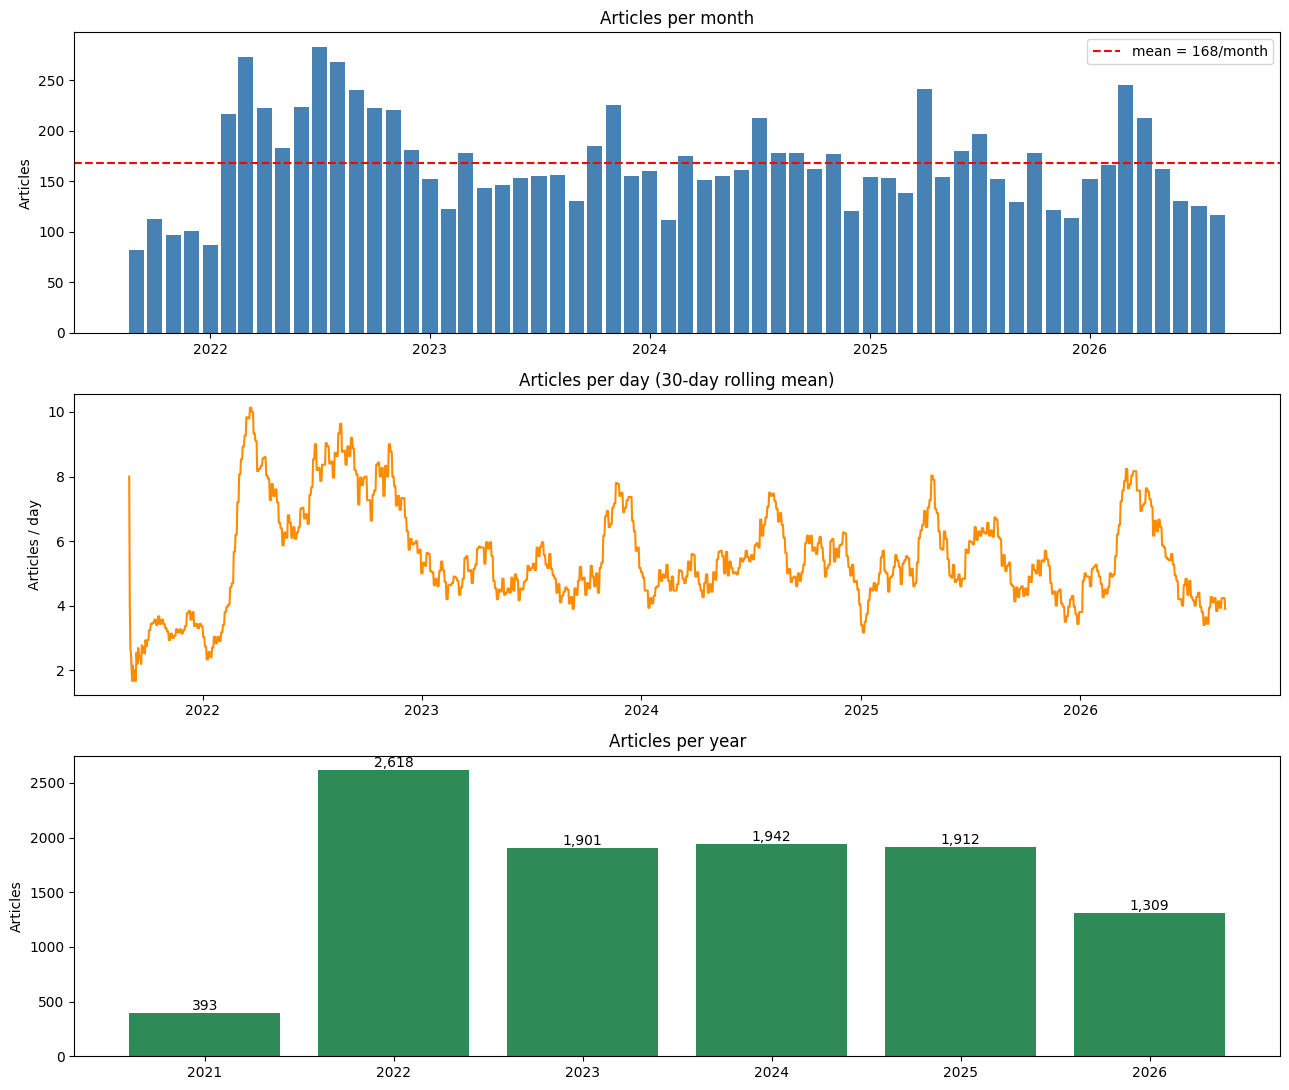

Days with 0 articles: 1218 of 1825
count     60.0
mean     167.9
std       46.3
min       82.0
25%      136.0
50%      158.0
75%      188.0
max      283.0
Name: count, dtype: float64


In [12]:
import matplotlib.pyplot as plt

ts = article_df["published_at"]

monthly = ts.dt.to_period("M").value_counts().sort_index()
monthly.index = monthly.index.to_timestamp()

# Daily counts including days with zero articles
daily = ts.dt.normalize().value_counts().sort_index()
daily = daily.reindex(pd.date_range(daily.index.min(), daily.index.max()), fill_value=0)

yearly = ts.dt.year.value_counts().sort_index()

fig, axes = plt.subplots(3, 1, figsize=(13, 11))

axes[0].bar(monthly.index, monthly.values, width=25, color="steelblue")
axes[0].axhline(monthly.mean(), color="red", ls="--", label=f"mean = {monthly.mean():.0f}/month")
axes[0].set_title("Articles per month")
axes[0].set_ylabel("Articles")
axes[0].legend()

axes[1].plot(daily.index, daily.rolling(30, min_periods=1).mean(), color="darkorange")
axes[1].set_title("Articles per day (30-day rolling mean)")
axes[1].set_ylabel("Articles / day")

axes[2].bar(yearly.index.astype(str), yearly.values, color="seagreen")
for i, v in enumerate(yearly.values):
    axes[2].text(i, v, f"{v:,}", ha="center", va="bottom")
axes[2].set_title("Articles per year")
axes[2].set_ylabel("Articles")

plt.tight_layout()
plt.show()

print(f"Days with 0 articles: {(daily == 0).sum()} of {len(daily)}")
print(monthly.describe().round(1))